### This notebook is to be used to test the robustness of the AWG-GPU code. The code generates randomized waveform/rearrangement commands for the AWG output to be monitored on a spectrum analyzer.

### DO NOT connect the AWG to AODs when running this code!!!!!

In [35]:
import socket
import numpy as np
from numpy.random import randint, rand
from random import sample
import matplotlib.pyplot as plt
import struct

# ipaddress = "192.168.1.199"  # when running on remote
ipaddress = "127.0.0.1" # when running on local
server_address = (ipaddress, 56456)

def TCPsend(command):
    clientsock = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
    clientsock.connect(server_address)
    clientsock.send(command.encode())
    clientsock.close()


def tidy(item):
    # recursively convert numpy arrays and lists to lists for tidier printing
    if isinstance(item, np.ndarray):
        return item.tolist()
    elif isinstance(item, list):
        return [tidy(x) for x in item]
    else:
        return item

In [14]:
def random_waveform(maximum:int=7, dynamic=True, max_dynamic:int=3, amp=False, frequency_range=[80e6,110e6]):
    # Print and generate the commands for a random waveform
    # Returns the command, the number of tones and the final frequencies;
    # the latter two are used for the randomized rearranger
    #
    # Arguments:
    # maximum: maximum possible number of tones per channel
    # dynamic: whether to generate dynamic tones
    # max_dynamic: maximum number of dynamic tones per channel
    # amp: whether to include amplitude coefficients
    # frequency_range: lower and upper bounds for generated frequencies (in Hz)

    assert maximum > 0
    assert frequency_range[0] < frequency_range[1]
    assert max_dynamic <= maximum

    static_num = [randint(0, maximum+1) for i in range(4)]
    dynamic_num = [0,0,0,0]
    if dynamic:
        dynamic_num = [randint(0, min(static_num[i], max_dynamic)+1) for i in range(4)]
        dynamic_indexes = [sample(range(0, static_num[i]),dynamic_num[i]) for i in range(4)]
    if amp:
        amp_list = [[],[],[],[]]
        for i in range(4):
            amp_sublist = [rand(static_num[i]) for i in range(4)]
            amp_list[i] = amp_sublist/np.sum(amp_sublist)*len(amp_sublist)
    frequency_list = [np.sort(rand(static_num[i])*(frequency_range[1]-frequency_range[0])+frequency_range[0]) for i in range(4)]
    destfreq_list = [[],[],[],[]]
    for i in range(4):
        for j in range(dynamic_num[i]):
            index = dynamic_indexes[i][j]

            if static_num[i] == 1:
                destfreq_list[i].append(2*0.75*(rand()-0.5)*min(frequency_range[1]-frequency_list[i][index],frequency_list[i][index]-frequency_range[0])
                                        +frequency_list[i][index])
            elif index ==0:
                destfreq_list[i].append(0.75*rand()*(frequency_list[i][index+1]-frequency_range[0])+
                                    frequency_range[0]+0.125*(frequency_list[i][index+1]-frequency_range[0]))
            elif index == static_num[i]-1:
                destfreq_list[i].append(0.75*rand()*(frequency_range[1]-frequency_list[i][index-1])+
                                    frequency_list[i][index-1]+0.125*(frequency_range[1]-frequency_list[i][index-1]))
            else:
                destfreq_list[i].append(0.75*rand()*(frequency_list[i][index+1]-frequency_list[i][index-1])+
                                    frequency_list[i][index-1]+0.125*(frequency_list[i][index+1]-frequency_list[i][index-1]))
                
    finalfreq_list = frequency_list.copy()
    if dynamic:
        for i in range(4):
            for j in range(dynamic_num[i]):
                finalfreq_list[i][dynamic_indexes[i][j]] = destfreq_list[i][j]


    print("Randomizer Ready!!!\n\n")
    print("Static tones: ", static_num,"\n")
    print("Static frequencies: ", tidy(frequency_list),"\n")
    if dynamic:
        print("Dynamic tones: ", dynamic_num,"\n")
        print("Dynamic indexes: ", tidy(dynamic_indexes),"\n")
    print("Final frequencies: ", tidy(finalfreq_list),"\n")
    if amp:
        print("Amplitudes: ", amp_list,"\n\n")

    command = ""
    if amp:
        command += "1,"
    else:
        command += "0,"
    
    for i in range(4):
        command += str(static_num[i])+","
    for i in range(4):
        command += str(dynamic_num[i])+","
    for i in range(4):
        for j in range(static_num[i]):
            command += str(round(frequency_list[i][j],2))+","
    if dynamic:
        for i in range(4):
            for j in range(dynamic_num[i]):
                command += str(round(destfreq_list[i][j],2))+","
        tone_counter = 0
        for i in range(4):
            for j in range(dynamic_num[i]):
                command += str(dynamic_indexes[i][j]+tone_counter) + ","
            tone_counter += static_num[i]
    if amp:
        for i in range(4):
            for j in range(static_num[i]):
                command += str(amp_list[i][j])+","
    
    command += "go"

    print("Generated command: ", command,"\n\n")

    return command, static_num, finalfreq_list



def random_rearrange(channel:int, total_num:int, frequencies):
    # Print and generate the commands for a random rearrange
    # channel: the channel to rearrange
    # total_num: the total number of existing tones in the channel
    # frequencies: the frequencies of the existing tones in the channel

    assert channel < 4 and channel >= 0
    assert total_num == len(frequencies)
    keep_num = randint(0,total_num) + 1
    dynamic_num = randint(0,keep_num + 1)
    keep_indexes = randint(0,total_num,size=keep_num)
    keepfreq_list = []
    for i in range(keep_num):
        keepfreq_list.append(frequencies[keep_indexes[i]])
    destfreq_list = []
    if dynamic_num > 0:
        dynamic_indexes = randint(0,keep_num,size=dynamic_num)
        for i in range(dynamic_num):
            index = dynamic_indexes[i]

            if keep_num == 1:
                destfreq_list.append(2*(rand()-0.5)*10e6+keepfreq_list[index])
            elif index == 0:
                destfreq_list.append(0.75*rand()*(keepfreq_list[index+1]-keepfreq_list[index]) + keepfreq_list[index])
            elif index == keep_num-1:
                destfreq_list.append(0.75*rand()*(keepfreq_list[index]-keepfreq_list[index-1])+
                                    keepfreq_list[index-1]+0.125*(keepfreq_list[index]-keepfreq_list[index-1]))
            else:
                destfreq_list.append(0.75*rand()*(keepfreq_list[index+1]-keepfreq_list[index-1])+
                                    keepfreq_list[index-1]+0.125*(keepfreq_list[index+1]-keepfreq_list[index-1]))
                
        for i in range(dynamic_num):
            keepfreq_list[dynamic_indexes[i]] = destfreq_list[i]
                
    print("Randomizer Ready!!!\n\n")
    print("Kept tones: ", keep_num,"\n")
    print("Kept indices: ", tidy(keep_indexes),"\n")
    if dynamic_num > 0:
        print("Dynamic tones: ", dynamic_num,"\n")
        print("Dynamic indices: ", tidy(dynamic_indexes),"\n")
    print("Final frequencies: ", keepfreq_list,"\n\n")


    command = str(channel)+","
    command += str(keep_num)+","
    command += str(dynamic_num)+","
    for i in range(keep_num):
        command += str(keep_indexes[i])+","
    for i in range(dynamic_num):
        command += str(destfreq_list[i])+","
    for i in range(dynamic_num):
        command += str(dynamic_indexes[i])+","
    command += "rearr"

    return command


    


In [84]:
scommand, tone_nums, finalfreqs =  random_waveform()
channel = 2
if tone_nums[channel] == 0:
    print("No tones to rearrange on channel ", channel, "!")
else:
    rcommand = random_rearrange(channel,tone_nums[channel],finalfreqs[channel])

TCPsend(scommand)
# TCPsend("continue")
# TCPsend(rcommand)

Randomizer Ready!!!


Static tones:  [3, 6, 1, 3] 

Static frequencies:  [[82874727.71960628, 94740756.08902897, 96525250.69891752], [81078167.1812836, 83024433.31299762, 93701640.28463367, 98482968.79938206, 99722444.77420631, 102613844.33578913], [104246705.81840569], [86510090.37245788, 92984659.15338388, 93614981.29647997]] 

Dynamic tones:  [1, 3, 0, 3] 

Dynamic indexes:  [[0], [5, 0, 4], [], [2, 1, 0]] 

Final frequencies:  [[82874727.71960628, 94740756.08902897, 96525250.69891752], [81078167.1812836, 83024433.31299762, 93701640.28463367, 98482968.79938206, 99722444.77420631, 102613844.33578913], [104246705.81840569], [86510090.37245788, 92984659.15338388, 93614981.29647997]] 

Generated command:  0,3,6,1,3,1,3,0,3,82874727.72,94740756.09,96525250.7,81078167.18,83024433.31,93701640.28,98482968.8,99722444.77,102613844.34,104246705.82,86510090.37,92984659.15,93614981.3,82874727.72,102613844.34,81078167.18,99722444.77,93614981.3,92984659.15,86510090.37,0,8,3,7,12,11,10,go 


Random

In [94]:
def read_fft4ch(filename):
    with open(filename, "rb") as f:
        n = struct.unpack("<Q", f.read(8))[0]
        timestamp = struct.unpack("<d", f.read(8))[0]
        freqlist = np.fromfile(f, dtype="<f8", count = n)
        values = np.fromfile(f, dtype="<f4", count=4 * n)

    print("N = ", n)
    print("Timestamp = ", timestamp)


    if values.size != 4 * n:
        raise ValueError("File ended before all FFT data were read")

    # A Python list containing four independent number arrays.
    spectra = [
        values[0 : n].copy(),
        values[n : 2 * n].copy(),
        values[2 * n : 3 * n].copy(),
        values[3 * n : 4 * n].copy(),
    ]

    return freqlist,np.array(spectra)


freqlist,spectra = read_fft4ch("spectrum_analyzer_output_2026-09-30_13-24-00.bin")

N =  4096
Timestamp =  0.0


(80000000.0, 110000000.0)

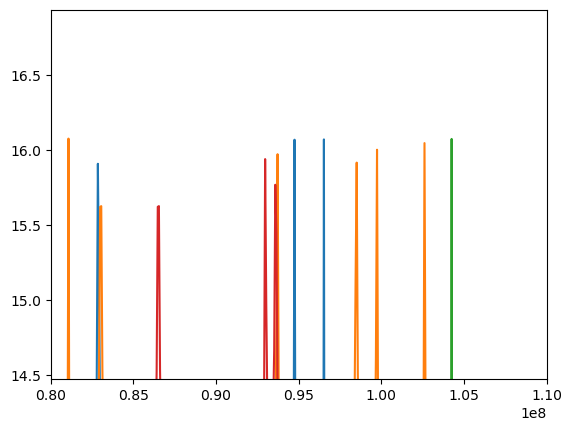

In [99]:
plt.plot(freqlist, np.log(spectra[0]))
plt.plot(freqlist, np.log(spectra[1]))
plt.plot(freqlist, np.log(spectra[2]))
plt.plot(freqlist, np.log(spectra[3]))
plt.xlim(left=0)
plt.ylim(bottom=0.9*np.max([np.log(spectra.flatten())]))
plt.xlim([80e6,110e6])
